# GE boxplots and heatmaps
Following recommendations from my committee, I'm going to pull all DEGs and plot expression as a dotplot/boxplot to identify up-/down-regulation and pick up patterns across treatments more easily

## 0. load libraries

In [118]:
library(tidyverse)
library(RColorBrewer)
library(pheatmap)

## 1. read CSVs

### phase 1

#### all genes

In [28]:
# get list of files
files <- list.files(
    path = '/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase1_v_phase1/deseq_res/prefilter_deseq',
    pattern = '\\.csv$',
    full.names = TRUE
    )

head(files)

[1] "/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase1_v_phase1/deseq_res/prefilter_deseq/p1_vst.csv"        
[2] "/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase1_v_phase1/deseq_res/prefilter_deseq/p1.both_v_cont.csv"
[3] "/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase1_v_phase1/deseq_res/prefilter_deseq/p1.hyp_v_both.csv" 
[4] "/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase1_v_phase1/deseq_res/prefilter_deseq/p1.hyp_v_cont.csv" 
[5] "/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase1_v_phase1/deseq_res/prefilter_deseq/p1.hyp_v_warm.csv" 
[6] "/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase1_v_phase1/deseq_res/prefilter_deseq/p1.warm_v_both.csv"

In [29]:
names(files) <-gsub('p1.', '', tools::file_path_sans_ext(basename(files)))
df_list <- lapply(files, read.csv)
names(df_list)
length(df_list)

[1] "vst"         "both_v_cont" "hyp_v_both"  "hyp_v_cont"  "hyp_v_warm" 
[6] "warm_v_both" "warm_v_cont"

[1] 7

In [30]:
# pull out the vst file
p1.vst <- df_list$vst

In [31]:
# remove vst from df_list
df_list$vst <- NULL

In [32]:
p1.list <- lapply(df_list, function(df) {
    df %>% rename('Gene' = X)
})

head(p1.list$both_v_cont)

,Gene,baseMean,log2FoldChange,lfcSE,pvalue,padj
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,LOC144621260,2772.7662,0.0006760298,0.02228152,7.787130e-01,0.996753837
2,LOC144621269,6797.3814,0.0043068296,0.10994540,5.813767e-01,0.992028790
3,LOC111120925,191.4430,-4.8969080894,1.40934377,8.354541e-06,0.003582926
4,LOC144621283,932.0540,0.0011781837,0.02371160,6.197830e-01,0.992275338
5,LOC144621276,12350.8892,0.0012266259,0.02481032,5.976185e-01,0.992028790
6,LOC111115920,213.3386,0.0676056817,0.25031860,6.160028e-03,0.234877458


In [56]:
p1.all.df <- bind_rows(p1.list, .id = "comparison")
head(p1.all.df)

,comparison,Gene,baseMean,log2FoldChange,lfcSE,pvalue,padj
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,both_v_cont,LOC144621260,2772.7662,0.0006760298,0.02228152,7.787130e-01,0.996753837
2,both_v_cont,LOC144621269,6797.3814,0.0043068296,0.10994540,5.813767e-01,0.992028790
3,both_v_cont,LOC111120925,191.4430,-4.8969080894,1.40934377,8.354541e-06,0.003582926
4,both_v_cont,LOC144621283,932.0540,0.0011781837,0.02371160,6.197830e-01,0.992275338
5,both_v_cont,LOC144621276,12350.8892,0.0012266259,0.02481032,5.976185e-01,0.992028790
6,both_v_cont,LOC111115920,213.3386,0.0676056817,0.25031860,6.160028e-03,0.234877458


#### DEGs

In [34]:
p1.deg <- lapply(p1.list, function(df) {
    df %>% dplyr::filter(abs(log2FoldChange) >= "1" & padj <= 0.05)
})

names(p1.deg)
head(p1.deg$both_v_cont)

[1] "both_v_cont" "hyp_v_both"  "hyp_v_cont"  "hyp_v_warm"  "warm_v_both"
[6] "warm_v_cont"

,Gene,baseMean,log2FoldChange,lfcSE,pvalue,padj
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,LOC111120925,191.44305,-4.896908,1.409344,8.354541e-06,0.003582926
2,LOC111103173,15.14959,4.218534,2.190562,7.946660e-05,0.015793180
3,LOC111105159,57.17908,-5.231786,2.548807,4.742151e-05,0.010936026
4,LOC111132252,110.19476,-2.652227,2.036381,2.797628e-04,0.035208785
5,LOC111137262,591.06709,3.700067,3.002875,2.185576e-04,0.029883595
6,LOC111105069,273.29807,-3.773655,2.837697,1.914828e-04,0.027102591


In [37]:
p1.deg.df <- bind_rows(p1.deg, .id = "comparison")
head(p1.deg.df)

,comparison,Gene,baseMean,log2FoldChange,lfcSE,pvalue,padj
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,both_v_cont,LOC111120925,191.44305,-4.896908,1.409344,8.354541e-06,0.003582926
2,both_v_cont,LOC111103173,15.14959,4.218534,2.190562,7.946660e-05,0.015793180
3,both_v_cont,LOC111105159,57.17908,-5.231786,2.548807,4.742151e-05,0.010936026
4,both_v_cont,LOC111132252,110.19476,-2.652227,2.036381,2.797628e-04,0.035208785
5,both_v_cont,LOC111137262,591.06709,3.700067,3.002875,2.185576e-04,0.029883595
6,both_v_cont,LOC111105069,273.29807,-3.773655,2.837697,1.914828e-04,0.027102591


#### vst

In [35]:
p1.vst <- p1.vst %>% 
pivot_longer(cols = -X,
             names_to = 'Sample',
             values_to = 'vst_expr') %>%
rename('Gene' = X)

head(p1.vst)

Gene,Sample,vst_expr
<chr>,<chr>,<dbl>
LOC144621260,B1_Nu_O03,11.21797
LOC144621260,B2_Nu_O12,11.93477
LOC144621260,B4_Nu_O32,11.22476
LOC144621260,B5_Nu_O36,11.38600
LOC144621260,B6_Nu_O47,11.49149
LOC144621260,C1_Nu_W01,11.33041


### phase 2

#### all genes

In [21]:
# get list of files
files <- list.files(
    path = '/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase2_v_phase2/deseq_res/prefilter_deseq',
    pattern = '\\.csv$',
    full.names = TRUE
    )

head(files)

[1] "/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase2_v_phase2/deseq_res/prefilter_deseq/bb_cc.csv"
[2] "/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase2_v_phase2/deseq_res/prefilter_deseq/bc_bb.csv"
[3] "/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase2_v_phase2/deseq_res/prefilter_deseq/bc_cc.csv"
[4] "/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase2_v_phase2/deseq_res/prefilter_deseq/bc_hc.csv"
[5] "/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase2_v_phase2/deseq_res/prefilter_deseq/bc_wc.csv"
[6] "/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase2_v_phase2/deseq_res/prefilter_deseq/bh_bb.csv"

In [22]:
names(files) <-tools::file_path_sans_ext(basename(files))
df_list <- lapply(files, read.csv)
names(df_list)
length(df_list)

[1] "bb_cc"        "bc_bb"        "bc_cc"        "bc_hc"        "bc_wc"       
 [6] "bh_bb"        "bh_bc"        "bh_bw"        "bh_ch"        "bh_hh"       
[11] "bw_bb"        "bw_bc"        "bw_cw"        "bw_ww"        "cb_bb"       
[16] "cb_bc"        "cb_cc"        "cb_ch"        "cb_cw"        "ch_cc"       
[21] "ch_hc"        "cw_cc"        "cw_ch"        "cw_wc"        "hb_bb"       
[26] "hb_bh"        "hb_cb"        "hb_hc"        "hb_hh"        "hb_hw"       
[31] "hc_cc"        "hc_hh"        "hh_cc"        "hh_ch"        "hw_bw"       
[36] "hw_cw"        "hw_hc"        "hw_hh"        "hw_ww"        "vst_filtered"
[41] "wb_bb"        "wb_bw"        "wb_cb"        "wb_hb"        "wb_wc"       
[46] "wb_wh"        "wb_ww"        "wc_cc"        "wc_hc"        "wc_ww"       
[51] "wh_bh"        "wh_ch"        "wh_hh"        "wh_hw"        "wh_wc"       
[56] "wh_ww"        "ww_cc"        "ww_cw"

[1] 58

In [24]:
# pull out the vst file
p2.vst <- df_list$vst_filtered

In [25]:
# remove vst from df_list
df_list$vst_filtered <- NULL

In [23]:
p2.list <- lapply(df_list, function(df) {
    df %>% rename('Gene' = X)
})

head(p2.list$bb_cc)

,Gene,baseMean,log2FoldChange,lfcSE,pvalue,padj
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,LOC144621260,1949.4353,0.010846306,0.1181696,0.853183094,0.9724506
2,LOC144621269,2097.0613,0.574046393,1.4166064,0.005417241,0.1414943
3,LOC111120925,132.0849,0.012669224,0.2188470,0.611221386,0.9005917
4,LOC144621283,866.8099,-0.007476253,0.1181756,0.898386832,0.9815658
5,LOC144621276,12195.3765,0.014976640,0.1055768,0.815501885,0.9615752
6,LOC111115920,171.8729,0.000658718,0.1373620,0.987225525,0.9965243


#### DEGs

In [26]:
p2.deg <- lapply(df_list, function(df) {
    df %>% dplyr::filter(abs(log2FoldChange) >= "1" & padj <= 0.05) %>%
    rename('Gene' = X)
})

names(p2.deg)
head(p2.deg$bb_cc)

[1] "bb_cc" "bc_bb" "bc_cc" "bc_hc" "bc_wc" "bh_bb" "bh_bc" "bh_bw" "bh_ch"
[10] "bh_hh" "bw_bb" "bw_bc" "bw_cw" "bw_ww" "cb_bb" "cb_bc" "cb_cc" "cb_ch"
[19] "cb_cw" "ch_cc" "ch_hc" "cw_cc" "cw_ch" "cw_wc" "hb_bb" "hb_bh" "hb_cb"
[28] "hb_hc" "hb_hh" "hb_hw" "hc_cc" "hc_hh" "hh_cc" "hh_ch" "hw_bw" "hw_cw"
[37] "hw_hc" "hw_hh" "hw_ww" "wb_bb" "wb_bw" "wb_cb" "wb_hb" "wb_wc" "wb_wh"
[46] "wb_ww" "wc_cc" "wc_hc" "wc_ww" "wh_bh" "wh_ch" "wh_hh" "wh_hw" "wh_wc"
[55] "wh_ww" "ww_cc" "ww_cw"

,Gene,baseMean,log2FoldChange,lfcSE,pvalue,padj
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,LOC111102506,934.47839,1.339691,1.467145,6.770792e-04,4.716118e-02
2,LOC144622036,59.15195,22.563229,3.737879,4.356750e-10,1.450507e-07
3,LOC144619234,20.26832,20.963235,3.227844,2.791179e-11,1.088996e-08
4,LOC144622046,14.97323,20.425457,3.453054,1.102275e-09,3.528692e-07
5,LOC111105159,68.18251,7.603607,3.282585,2.351238e-05,4.134536e-03
6,LOC144622060,65.28037,22.076677,3.249318,3.320122e-12,1.507335e-09


In [38]:
p2.deg.df <- bind_rows(p2.deg, .id = "comparison")
head(p2.deg.df)

,comparison,Gene,baseMean,log2FoldChange,lfcSE,pvalue,padj
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,bb_cc,LOC111102506,934.47839,1.339691,1.467145,6.770792e-04,4.716118e-02
2,bb_cc,LOC144622036,59.15195,22.563229,3.737879,4.356750e-10,1.450507e-07
3,bb_cc,LOC144619234,20.26832,20.963235,3.227844,2.791179e-11,1.088996e-08
4,bb_cc,LOC144622046,14.97323,20.425457,3.453054,1.102275e-09,3.528692e-07
5,bb_cc,LOC111105159,68.18251,7.603607,3.282585,2.351238e-05,4.134536e-03
6,bb_cc,LOC144622060,65.28037,22.076677,3.249318,3.320122e-12,1.507335e-09


#### vst

In [27]:
p2.vst <- p2.vst %>% 
pivot_longer(cols = -X,
             names_to = 'Sample',
             values_to = 'vst_expr') %>%
rename('Gene' = X)

head(p2.vst)

Gene,Sample,vst_expr
<chr>,<chr>,<dbl>
LOC144621260,B1_B1_O01,11.62347
LOC144621260,B1_W5_O50,11.42347
LOC144621260,B2_B5_O51,11.40884
LOC144621260,B2_C4_O40,11.27515
LOC144621260,B3_B4_O41,11.00057
LOC144621260,B3_C3_O30,10.98404


### metadata

In [48]:
meta <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/metaData/sample_metaData.csv')
head(meta)

,Sample,Phase1_treatment,Phase1_temp,Phase1_DO,Phase1_TankRep,Phase2_treatment,Phase2_temp,Phase2_DO,Phase2_TankRep
,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<int>
1,B1_B1_O01,both,warm,hypoxic,1,both,warm,hypoxic,1
2,B1_Nu_O03,both,warm,hypoxic,1,NA,NA,NA,NA
3,B1_W5_O50,both,warm,hypoxic,1,warm,warm,normoxic,5
4,B2_B5_O51,both,warm,hypoxic,2,both,warm,hypoxic,5
5,B2_C4_O40,both,warm,hypoxic,2,control,ambient,normoxic,4
6,B2_Nu_O12,both,warm,hypoxic,2,NA,NA,NA,NA


In [51]:
p1.meta.vst <- merge(p1.vst, meta, by = 'Sample')
head(p1.meta.vst)

,Sample,Gene,vst_expr,Phase1_treatment,Phase1_temp,Phase1_DO,Phase1_TankRep,Phase2_treatment,Phase2_temp,Phase2_DO,Phase2_TankRep
,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<int>
1,B1_Nu_O03,LOC144621260,11.217975,both,warm,hypoxic,1,NA,NA,NA,NA
2,B1_Nu_O03,LOC144622680,5.806396,both,warm,hypoxic,1,NA,NA,NA,NA
3,B1_Nu_O03,LOC111117775,7.696555,both,warm,hypoxic,1,NA,NA,NA,NA
4,B1_Nu_O03,LOC111135353,11.210681,both,warm,hypoxic,1,NA,NA,NA,NA
5,B1_Nu_O03,LOC111106671,6.668376,both,warm,hypoxic,1,NA,NA,NA,NA
6,B1_Nu_O03,LOC111130564,11.353748,both,warm,hypoxic,1,NA,NA,NA,NA


## 2. plot phase 1 DEGs

starting with only the comparisons against control oysters

In [46]:
p1.control <- p1.deg.df %>% 
filter(grepl('cont', comparison)) %>%
separate_wider_delim(comparison, 
                     delim = "_v_", 
                     names = c("stress", "control"))

head(p1.control)

stress,control,Gene,baseMean,log2FoldChange,lfcSE,pvalue,padj
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
both,cont,LOC111120925,191.44305,-4.896908,1.409344,8.354541e-06,0.003582926
both,cont,LOC111103173,15.14959,4.218534,2.190562,7.946660e-05,0.015793180
both,cont,LOC111105159,57.17908,-5.231786,2.548807,4.742151e-05,0.010936026
both,cont,LOC111132252,110.19476,-2.652227,2.036381,2.797628e-04,0.035208785
both,cont,LOC111137262,591.06709,3.700067,3.002875,2.185576e-04,0.029883595
both,cont,LOC111105069,273.29807,-3.773655,2.837697,1.914828e-04,0.027102591


want a df that determines if a gene is a DEG and for which treatment
    

In [64]:
p1.all.df.subset <- p1.all.df %>%
# filter for all comparisons against control
filter(grepl('cont', comparison)) %>%
# separate comparison column
separate_wider_delim(comparison, 
                     delim = "_v_", 
                     names = c("stress", "control")) %>% 
# determine if a gene is a DEG or not
mutate(DEG = case_when(
    Gene %in% p1.control$Gene ~ stress,
    TRUE ~ 'NS'))

head(p1.all.df.subset)

stress,control,Gene,baseMean,log2FoldChange,lfcSE,pvalue,padj,DEG
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
both,cont,LOC144621260,2772.7662,0.0006760298,0.02228152,7.787130e-01,0.996753837,NS
both,cont,LOC144621269,6797.3814,0.0043068296,0.10994540,5.813767e-01,0.992028790,NS
both,cont,LOC111120925,191.4430,-4.8969080894,1.40934377,8.354541e-06,0.003582926,both
both,cont,LOC144621283,932.0540,0.0011781837,0.02371160,6.197830e-01,0.992275338,NS
both,cont,LOC144621276,12350.8892,0.0012266259,0.02481032,5.976185e-01,0.992028790,NS
both,cont,LOC111115920,213.3386,0.0676056817,0.25031860,6.160028e-03,0.234877458,NS


right now, vst is expression for each individual - I am imagining a boxplot of expression for all genes and highlighting the DEGs for each treatment. to do this, I think I need the average expression of each gene for each treatment instead of plotting each individual and gene 

In [70]:
p1.mean.vst <- p1.meta.vst %>%
  group_by(Phase1_treatment, Gene) %>%
  summarise(mean_vst = mean(vst_expr, na.rm = TRUE), .groups = "drop") %>%
mutate(DEG = case_when(
    Phase1_treatment == 'both' & Gene %in% p1.deg$both_v_cont$Gene ~ Phase1_treatment,
    Phase1_treatment == 'hypoxic' & Gene %in% p1.deg$hyp_v_cont$Gene ~ Phase1_treatment,
    Phase1_treatment == 'warm' & Gene %in% p1.deg$warm_v_cont$Gene ~ Phase1_treatment,
    TRUE ~ 'NS'))

head(p1.mean.vst)

Phase1_treatment,Gene,mean_vst,DEG
<chr>,<chr>,<dbl>,<chr>
both,LOC111099029,8.167239,NS
both,LOC111099030,5.935543,NS
both,LOC111099037,5.806396,NS
both,LOC111099039,6.523243,NS
both,LOC111099040,11.952726,NS
both,LOC111099041,10.419968,NS


In [71]:
unique(p1.mean.vst$DEG)

[1] "NS"      "both"    "hypoxic" "warm"

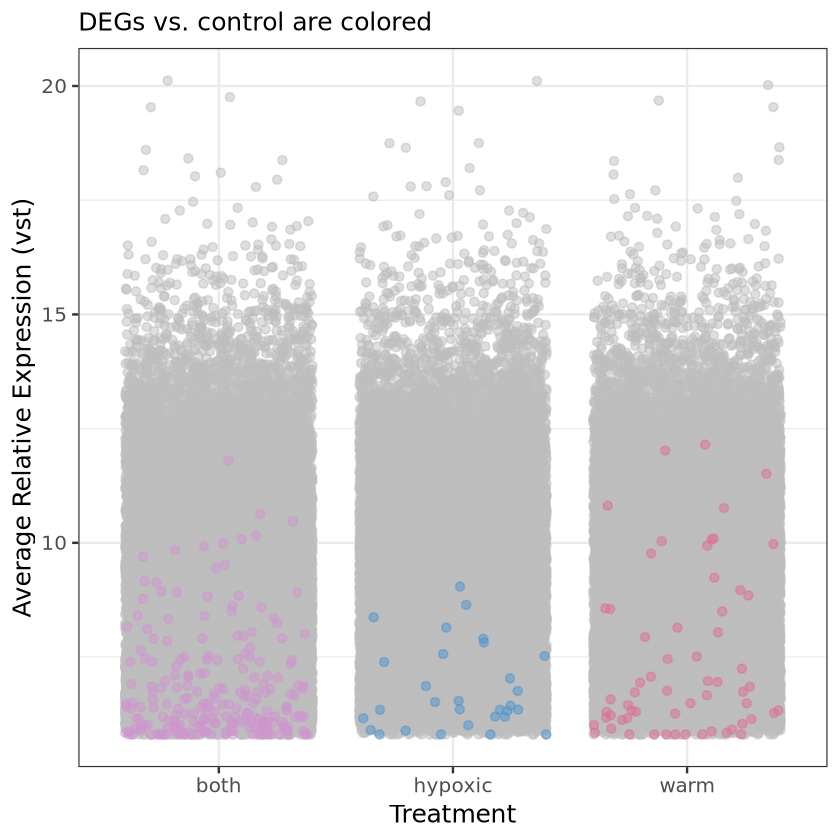

In [80]:
plot.df <- p1.mean.vst %>%
  filter(Phase1_treatment != 'control') %>%
  arrange(DEG != "NS")   # NS (FALSE) first, DEGs (TRUE) last = drawn on top

ggplot(plot.df, aes(x = Phase1_treatment, y = mean_vst, col = DEG)) +
  geom_jitter(alpha = 0.5) +
  scale_color_manual(values = c(
    "hypoxic" = "steelblue3",
    "warm"    = "palevioletred",
    "NS"      = "grey",
    "both"    = "plum3")) +
  theme_bw(base_size = 15) +
guides(col = 'none') +
labs(x = 'Treatment', 
     y = 'Average Relative Expression (vst)',
    subtitle = 'DEGs vs. control are colored')

i'm not sure if this is actually what I want ...

plotting all expression (not just mean expression for each gene across treatments)

### warm vs. control DEGs

In [97]:
# assign higher expression direction
wc.deg <- p1.deg$warm_v_cont %>%
mutate(higher_expr = case_when(
    log2FoldChange > 1 ~ 'Warm',
    log2FoldChange < 1 ~ 'Control'))

# pull W vs. C DEGs vst data
warm_deg.vst <- p1.meta.vst %>%
filter(Gene %in% p1.deg$warm_v_cont$Gene)

# add higher expression direction
warm_deg.vst <- merge(warm_deg.vst, wc.deg, by = 'Gene')

head(warm_deg.vst)

,Gene,Sample,vst_expr,Phase1_treatment,Phase1_temp,Phase1_DO,Phase1_TankRep,Phase2_treatment,Phase2_temp,Phase2_DO,Phase2_TankRep,baseMean,log2FoldChange,lfcSE,pvalue,padj,higher_expr
,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,LOC111099646,H4_Nu_B28,6.480932,hypoxic,ambient,hypoxic,4,NA,NA,NA,NA,291.0188,-5.46517,1.248325,2.505487e-07,0.0004164787,Control
2,LOC111099646,C1_Nu_W01,11.252479,control,ambient,normoxic,1,NA,NA,NA,NA,291.0188,-5.46517,1.248325,2.505487e-07,0.0004164787,Control
3,LOC111099646,W4_Nu_G27,6.068171,warm,warm,normoxic,4,NA,NA,NA,NA,291.0188,-5.46517,1.248325,2.505487e-07,0.0004164787,Control
4,LOC111099646,B5_Nu_O36,7.654404,both,warm,hypoxic,5,NA,NA,NA,NA,291.0188,-5.46517,1.248325,2.505487e-07,0.0004164787,Control
5,LOC111099646,B1_Nu_O03,6.058625,both,warm,hypoxic,1,NA,NA,NA,NA,291.0188,-5.46517,1.248325,2.505487e-07,0.0004164787,Control
6,LOC111099646,W6_Nu_G41,6.712817,warm,warm,normoxic,6,NA,NA,NA,NA,291.0188,-5.46517,1.248325,2.505487e-07,0.0004164787,Control


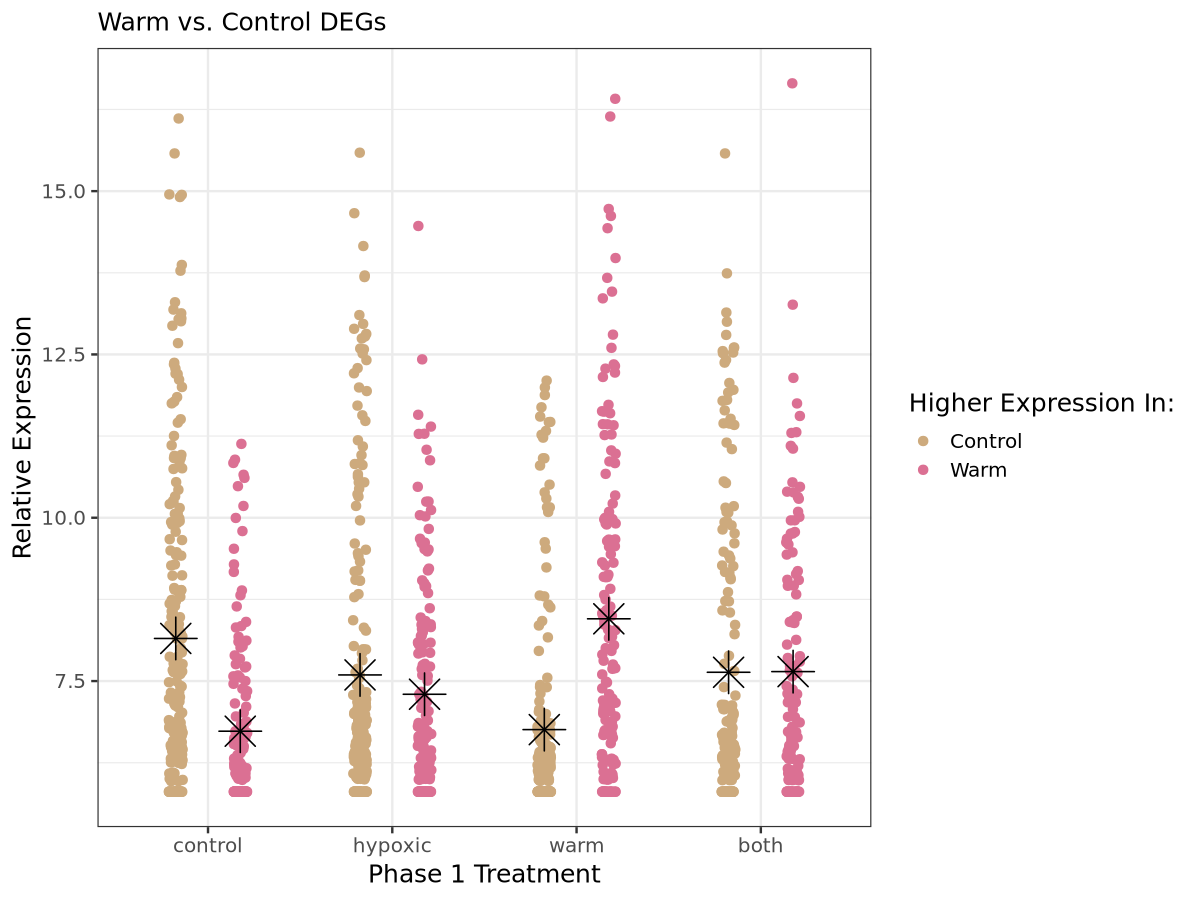

In [108]:
options(repr.plot.height = 7.5, repr.plot.width = 10)

# set dodge position
dodge <- 0.7

# set factor levels
warm_deg.vst$Phase1_treatment <- factor(warm_deg.vst$Phase1_treatment, levels = c('control', 'hypoxic', 'warm', 'both'))

# plot
ggplot(warm_deg.vst, aes(x = Phase1_treatment, y = vst_expr,
                         col = higher_expr, group = higher_expr)) +
geom_point(position = position_jitterdodge(jitter.width = 0.15,
                                             dodge.width = dodge,
                                             seed = 1)) +
stat_summary(
    fun = "mean", 
    geom = "point", 
    position = position_dodge(width = dodge),
    shape = 8,      # asterick shape
    size = 8,        # Size of the point
    color = "black"  # Outline color
  ) +
theme_bw(base_size = 15) +
scale_color_manual(values = c('Control' = 'burlywood3', 'Warm' = 'palevioletred')) +
labs(x = 'Phase 1 Treatment',
     y = 'Relative Expression',
     color = 'Higher Expression In:',
    subtitle = 'Warm vs. Control DEGs')

In [115]:
warm.deg.mat <- warm_deg.vst %>% 
select(Gene, Sample, vst_expr) %>%
pivot_wider(
    names_from = Sample,
    values_from = vst_expr) %>%
column_to_rownames('Gene') %>%
as.matrix()

In [121]:
annotation <- meta %>%
  select(Sample, Phase1_treatment) %>%
  column_to_rownames("Sample")

annotation <- annotation[colnames(warm.deg.mat), , drop = FALSE]

annotation_colors <- list(
  Phase1_treatment = c(
    control = "burlywood3",
    warm = "palevioletred",
      hypoxic = 'steelblue3',
      both = 'plum3'
  )
)

head(annotation)
head(annotation_colors)

,Phase1_treatment
,<chr>
H4_Nu_B28,hypoxic
C1_Nu_W01,control
W4_Nu_G27,warm
B5_Nu_O36,both
B1_Nu_O03,both
W6_Nu_G41,warm


$Phase1_treatment
        control            warm         hypoxic            both 
   "burlywood3" "palevioletred"    "steelblue3"         "plum3"

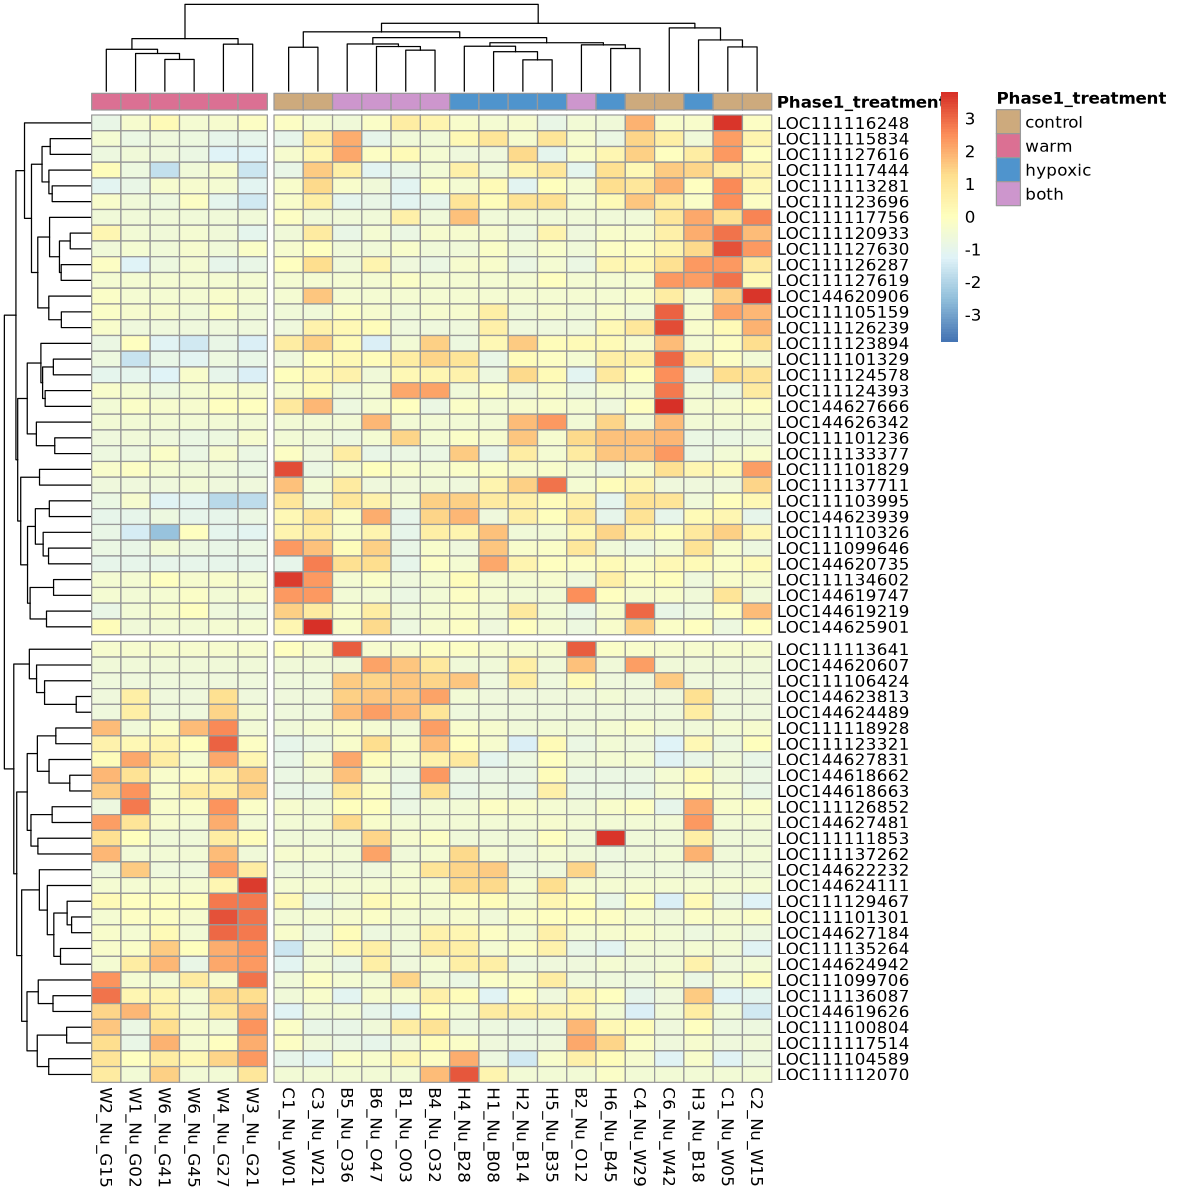

In [122]:
options(repr.plot.height = 10, repr.plot.width = 10)

pheatmap(warm.deg.mat,
         # cluster_cols = FALSE,
       annotation_col = annotation,
        annotation_colors = annotation_colors,
         cutree_rows = 2, 
         cutree_cols = 2,
        scale = 'row' # standardizes each gene separately across samples
        ) 

all of the warm samples cluster together - and there doesn't seem to be much overlap with the other treatments (they have intermediate levels of expression, some dark hot spots with the both treatment

In [128]:
cols <- colnames(warm.deg.mat)

ordered <- unlist(lapply(c("C", "H", "W", "B"), function(p) {
  sort(grep(paste0("^", p), cols, value = TRUE))
}))

warm.deg.mat <- warm.deg.mat[, ordered]

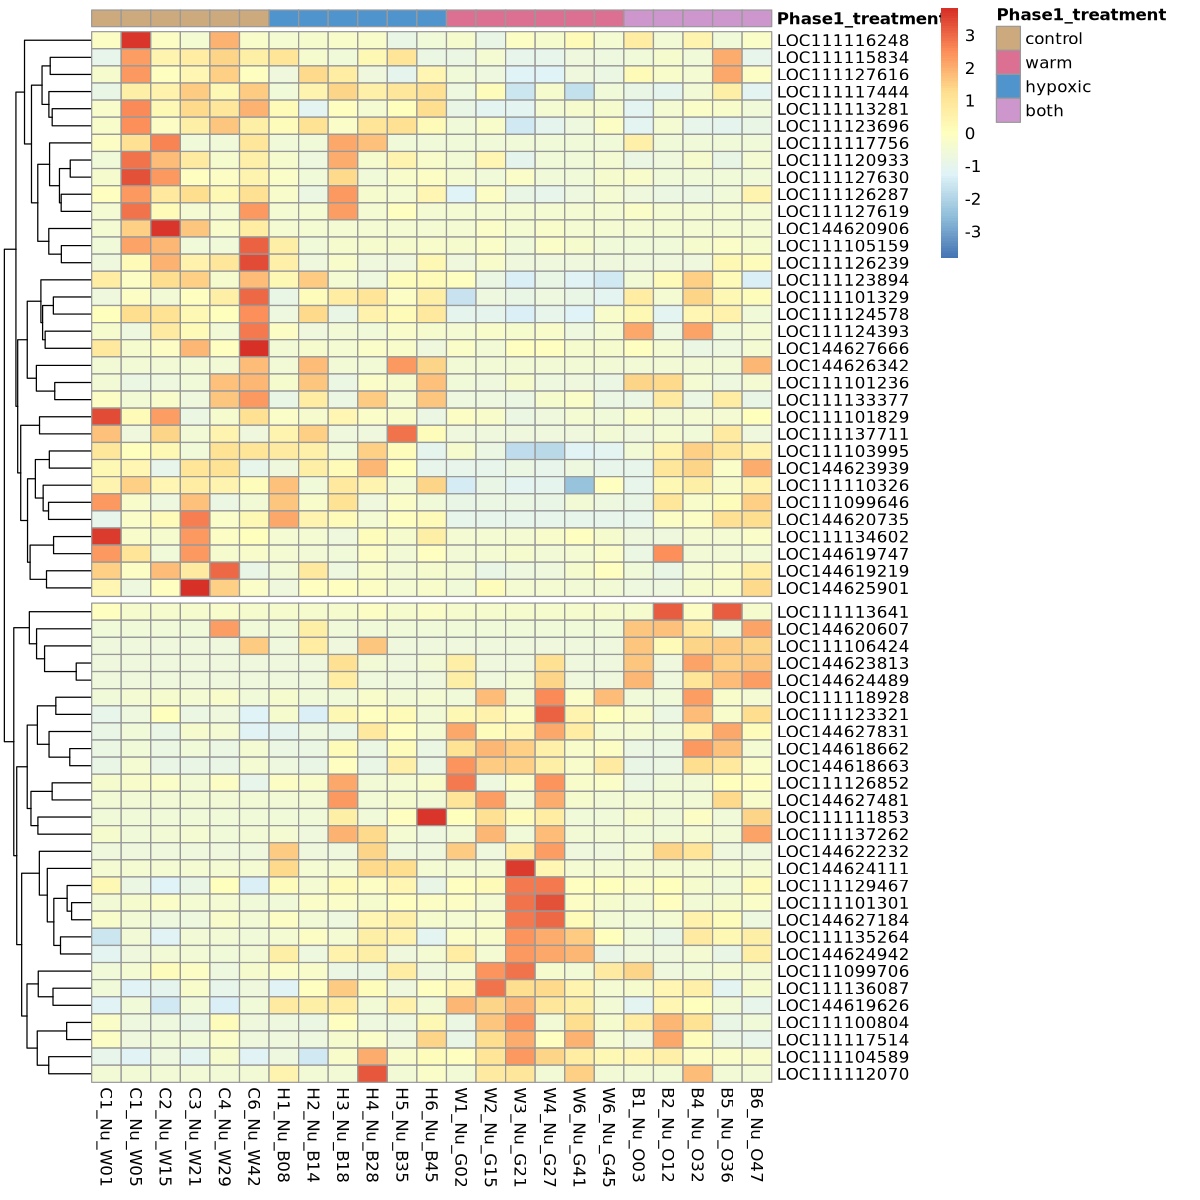

In [129]:
options(repr.plot.height = 10, repr.plot.width = 10)

pheatmap(warm.deg.mat,
          cluster_cols = FALSE,
       annotation_col = annotation,
        annotation_colors = annotation_colors,
         cutree_rows = 2, 
         cutree_cols = 2,
        scale = 'row' # standardizes each gene separately across samples
        ) 

when I don't let the program cluster the samples and instead have them ordered by their treatment, you can see that hypoxic samples kinda look like control, and both kinda look like warm

### hypoxic vs. control DEGs

In [130]:
# assign higher expression direction
hc.deg <- p1.deg$hyp_v_cont %>%
mutate(higher_expr = case_when(
    log2FoldChange > 1 ~ 'Hypoxic',
    log2FoldChange < 1 ~ 'Control'))

# pull W vs. C DEGs vst data
hyp_deg.vst <- p1.meta.vst %>%
filter(Gene %in% p1.deg$hyp_v_cont$Gene)

# add higher expression direction
hyp_deg.vst <- merge(hyp_deg.vst, hc.deg, by = 'Gene')

head(hyp_deg.vst)

,Gene,Sample,vst_expr,Phase1_treatment,Phase1_temp,Phase1_DO,Phase1_TankRep,Phase2_treatment,Phase2_temp,Phase2_DO,Phase2_TankRep,baseMean,log2FoldChange,lfcSE,pvalue,padj,higher_expr
,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,LOC111100041,B1_Nu_O03,6.162650,both,warm,hypoxic,1,NA,NA,NA,NA,736.0732,5.723808,2.865577,5.321702e-06,0.006983753,Hypoxic
2,LOC111100041,W1_Nu_G02,6.580028,warm,warm,normoxic,1,NA,NA,NA,NA,736.0732,5.723808,2.865577,5.321702e-06,0.006983753,Hypoxic
3,LOC111100041,H5_Nu_B35,5.806396,hypoxic,ambient,hypoxic,5,NA,NA,NA,NA,736.0732,5.723808,2.865577,5.321702e-06,0.006983753,Hypoxic
4,LOC111100041,B4_Nu_O32,9.924710,both,warm,hypoxic,4,NA,NA,NA,NA,736.0732,5.723808,2.865577,5.321702e-06,0.006983753,Hypoxic
5,LOC111100041,C1_Nu_W01,6.660921,control,ambient,normoxic,1,NA,NA,NA,NA,736.0732,5.723808,2.865577,5.321702e-06,0.006983753,Hypoxic
6,LOC111100041,C3_Nu_W21,6.285293,control,ambient,normoxic,3,NA,NA,NA,NA,736.0732,5.723808,2.865577,5.321702e-06,0.006983753,Hypoxic


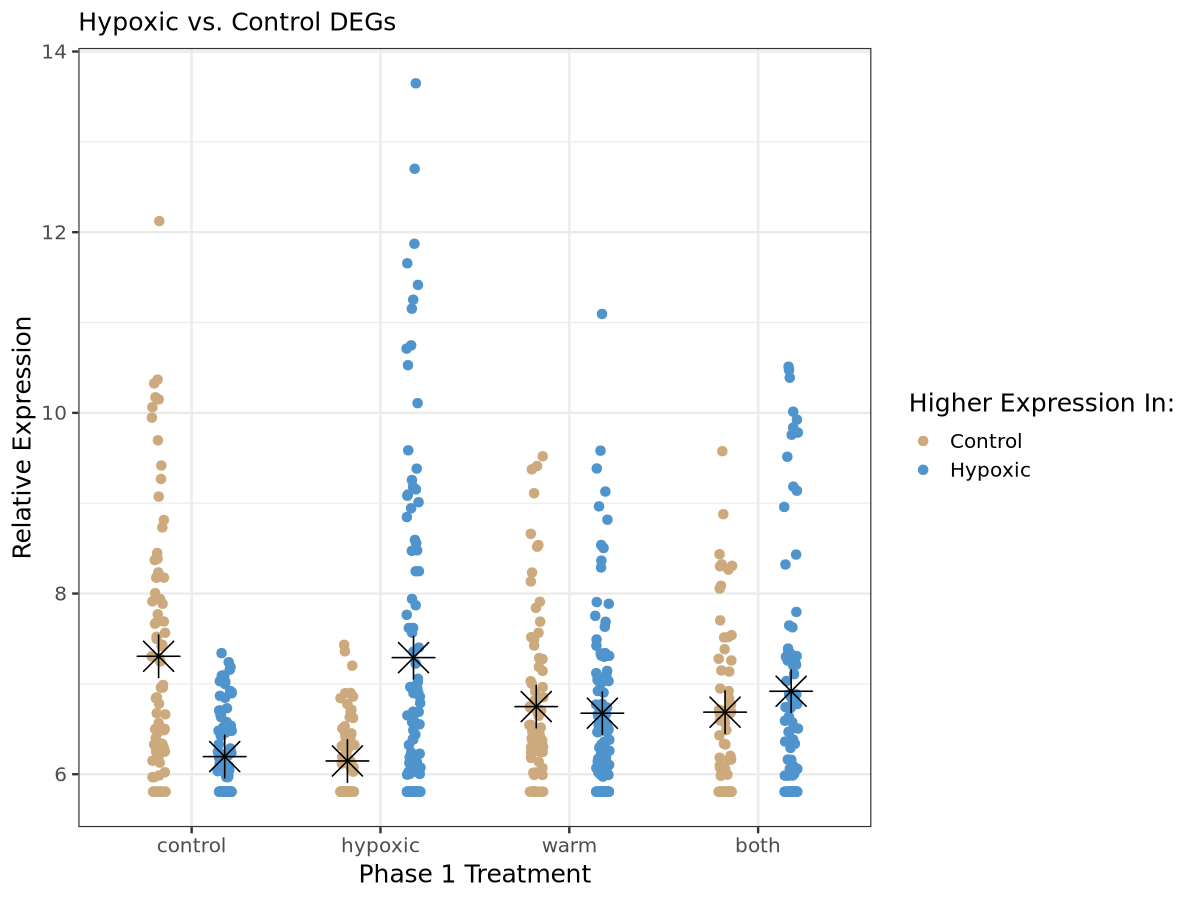

In [131]:
options(repr.plot.height = 7.5, repr.plot.width = 10)

# set dodge position
dodge <- 0.7

# set factor levels
hyp_deg.vst$Phase1_treatment <- factor(hyp_deg.vst$Phase1_treatment, levels = c('control', 'hypoxic', 'warm', 'both'))

# plot
ggplot(hyp_deg.vst, aes(x = Phase1_treatment, y = vst_expr,
                         col = higher_expr, group = higher_expr)) +
geom_point(position = position_jitterdodge(jitter.width = 0.15,
                                             dodge.width = dodge,
                                             seed = 1)) +
stat_summary(
    fun = "mean", 
    geom = "point", 
    position = position_dodge(width = dodge),
    shape = 8,      # asterick shape
    size = 8,        # Size of the point
    color = "black"  # Outline color
  ) +
theme_bw(base_size = 15) +
scale_color_manual(values = c('Control' = 'burlywood3', 'Hypoxic' = 'steelblue3')) +
labs(x = 'Phase 1 Treatment',
     y = 'Relative Expression',
     color = 'Higher Expression In:',
    subtitle = 'Hypoxic vs. Control DEGs')

In [133]:
hyp.deg.mat <- hyp_deg.vst %>% 
select(Gene, Sample, vst_expr) %>%
pivot_wider(
    names_from = Sample,
    values_from = vst_expr) %>%
column_to_rownames('Gene') %>%
as.matrix()

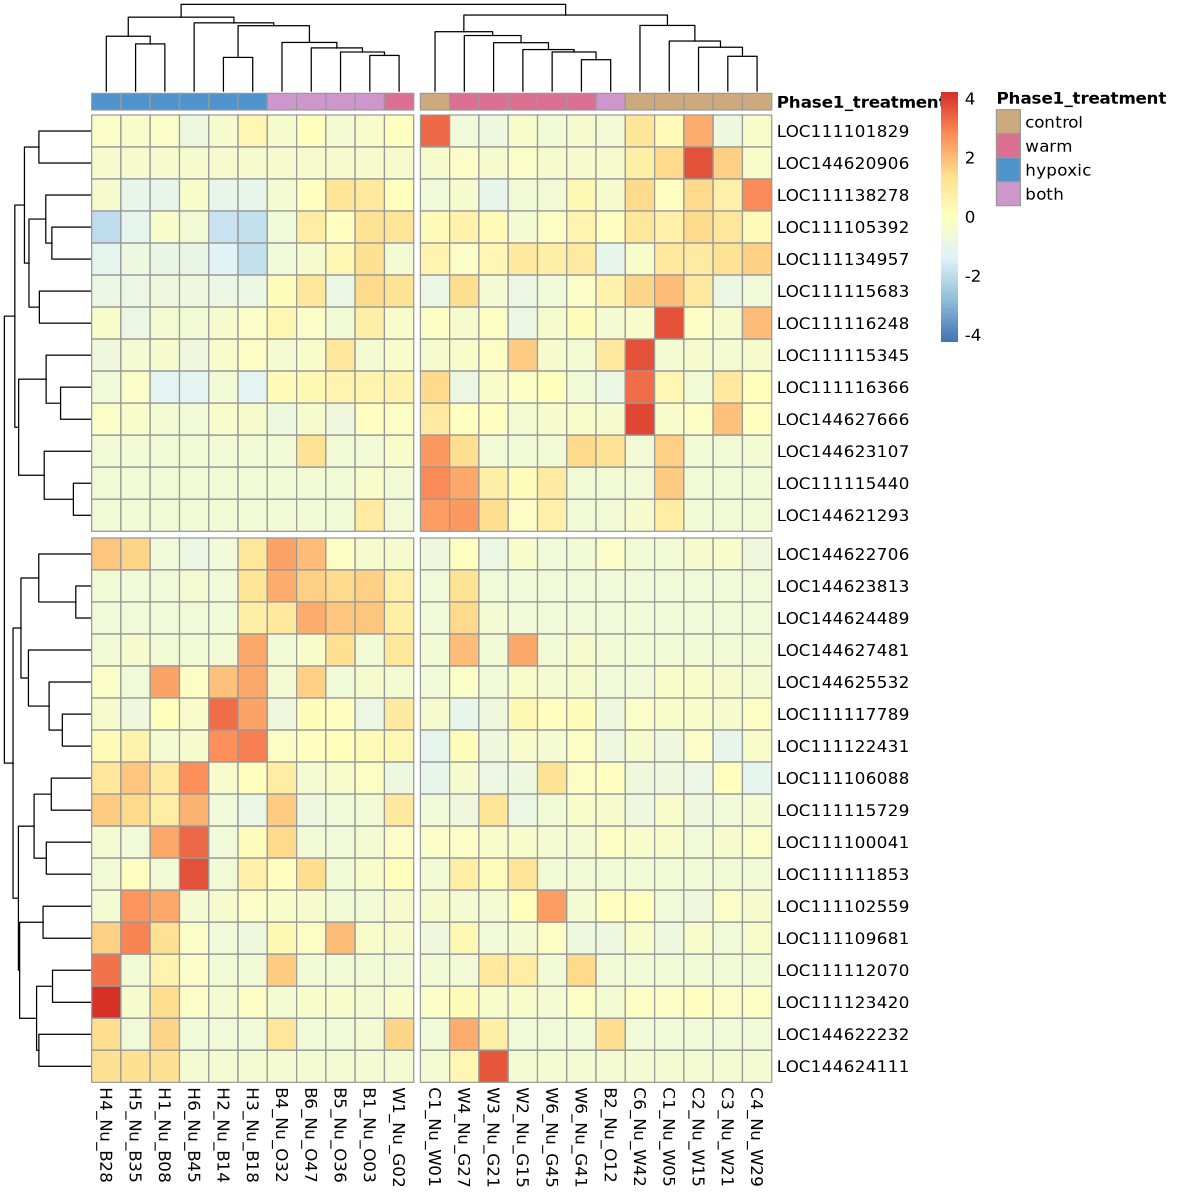

In [134]:
options(repr.plot.height = 10, repr.plot.width = 10)

pheatmap(hyp.deg.mat,
         # cluster_cols = FALSE,
       annotation_col = annotation,
        annotation_colors = annotation_colors,
         cutree_rows = 2, 
         cutree_cols = 2,
        scale = 'row' # standardizes each gene separately across samples
        ) 

all of the hypoxic and most of the both samples cluster togehter which is interesting

In [135]:
cols <- colnames(hyp.deg.mat)

ordered <- unlist(lapply(c("C", "H", "W", "B"), function(p) {
  sort(grep(paste0("^", p), cols, value = TRUE))
}))

hyp.deg.mat <- hyp.deg.mat[, ordered]

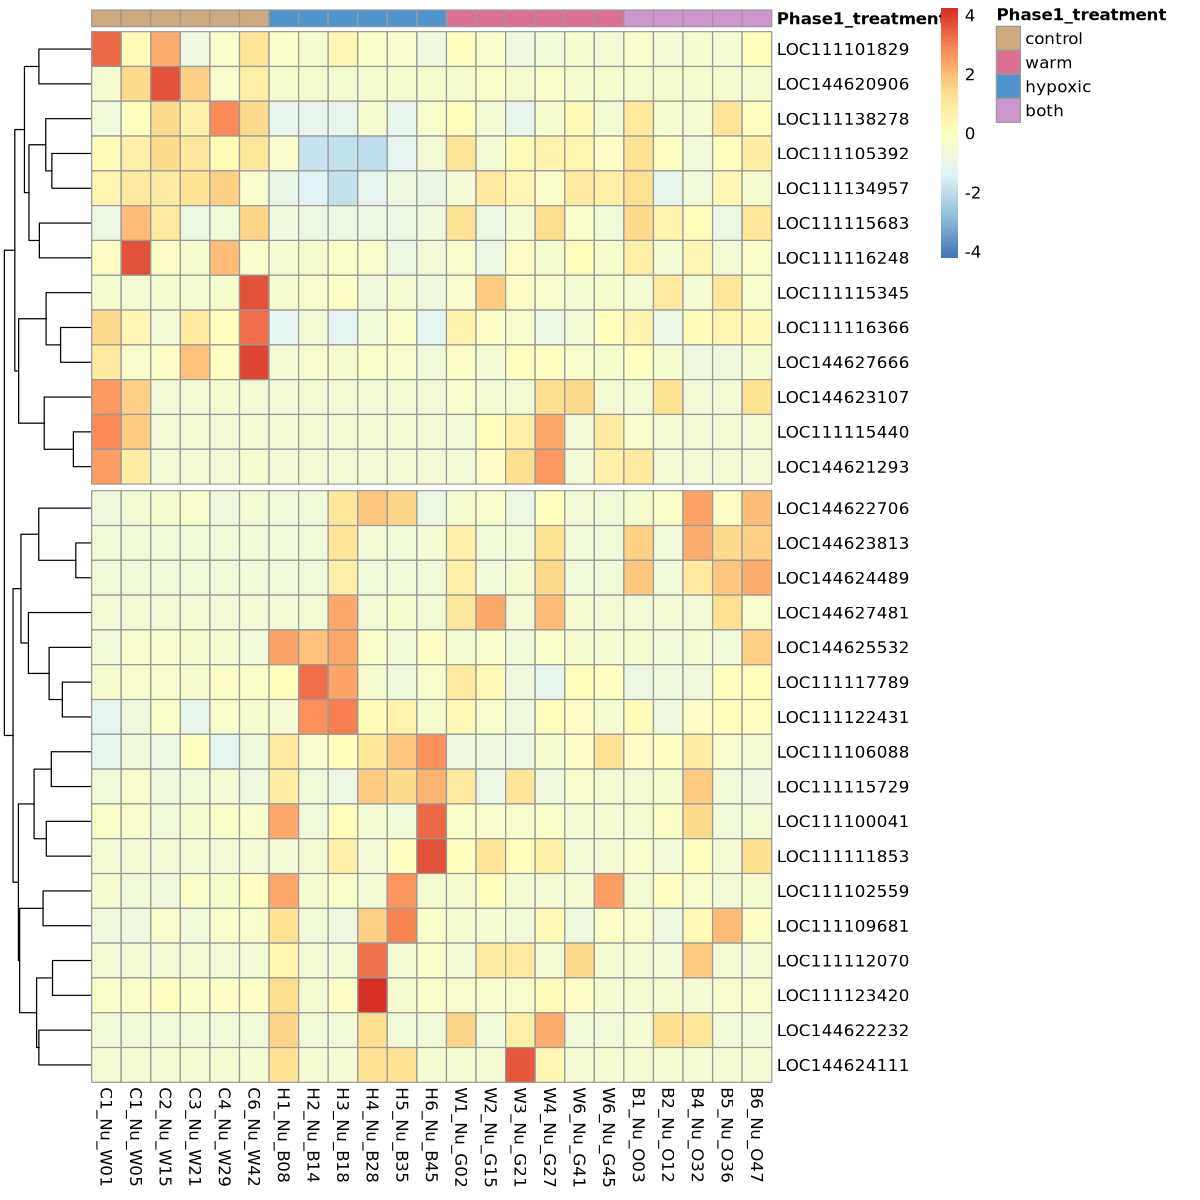

In [136]:
options(repr.plot.height = 10, repr.plot.width = 10)

pheatmap(hyp.deg.mat,
          cluster_cols = FALSE,
       annotation_col = annotation,
        annotation_colors = annotation_colors,
         cutree_rows = 2, 
         cutree_cols = 2,
        scale = 'row' # standardizes each gene separately across samples
        ) 

warm and both treatments have more intermediate/higher expression of the DEGs between H vs. C

### both vs. control DEGs

In [143]:
# assign higher expression direction
bc.deg <- p1.deg$both_v_cont %>%
mutate(higher_expr = case_when(
    log2FoldChange > 1 ~ 'Both',
    log2FoldChange < 1 ~ 'Control'))

# pull B vs. C DEGs vst data
both_deg.vst <- p1.meta.vst %>%
filter(Gene %in% p1.deg$both_v_cont$Gene)

# add higher expression direction
both_deg.vst <- merge(both_deg.vst, bc.deg, by = 'Gene')

head(both_deg.vst)

,Gene,Sample,vst_expr,Phase1_treatment,Phase1_temp,Phase1_DO,Phase1_TankRep,Phase2_treatment,Phase2_temp,Phase2_DO,Phase2_TankRep,baseMean,log2FoldChange,lfcSE,pvalue,padj,higher_expr
,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,LOC111099801,C2_Nu_W15,11.324592,control,ambient,normoxic,2,NA,NA,NA,NA,855.5302,-7.473097,1.560999,5.141618e-08,4.054415e-05,Control
2,LOC111099801,B4_Nu_O32,5.806396,both,warm,hypoxic,4,NA,NA,NA,NA,855.5302,-7.473097,1.560999,5.141618e-08,4.054415e-05,Control
3,LOC111099801,B1_Nu_O03,6.058625,both,warm,hypoxic,1,NA,NA,NA,NA,855.5302,-7.473097,1.560999,5.141618e-08,4.054415e-05,Control
4,LOC111099801,C1_Nu_W01,10.242533,control,ambient,normoxic,1,NA,NA,NA,NA,855.5302,-7.473097,1.560999,5.141618e-08,4.054415e-05,Control
5,LOC111099801,C1_Nu_W05,10.593325,control,ambient,normoxic,1,NA,NA,NA,NA,855.5302,-7.473097,1.560999,5.141618e-08,4.054415e-05,Control
6,LOC111099801,B5_Nu_O36,6.097391,both,warm,hypoxic,5,NA,NA,NA,NA,855.5302,-7.473097,1.560999,5.141618e-08,4.054415e-05,Control


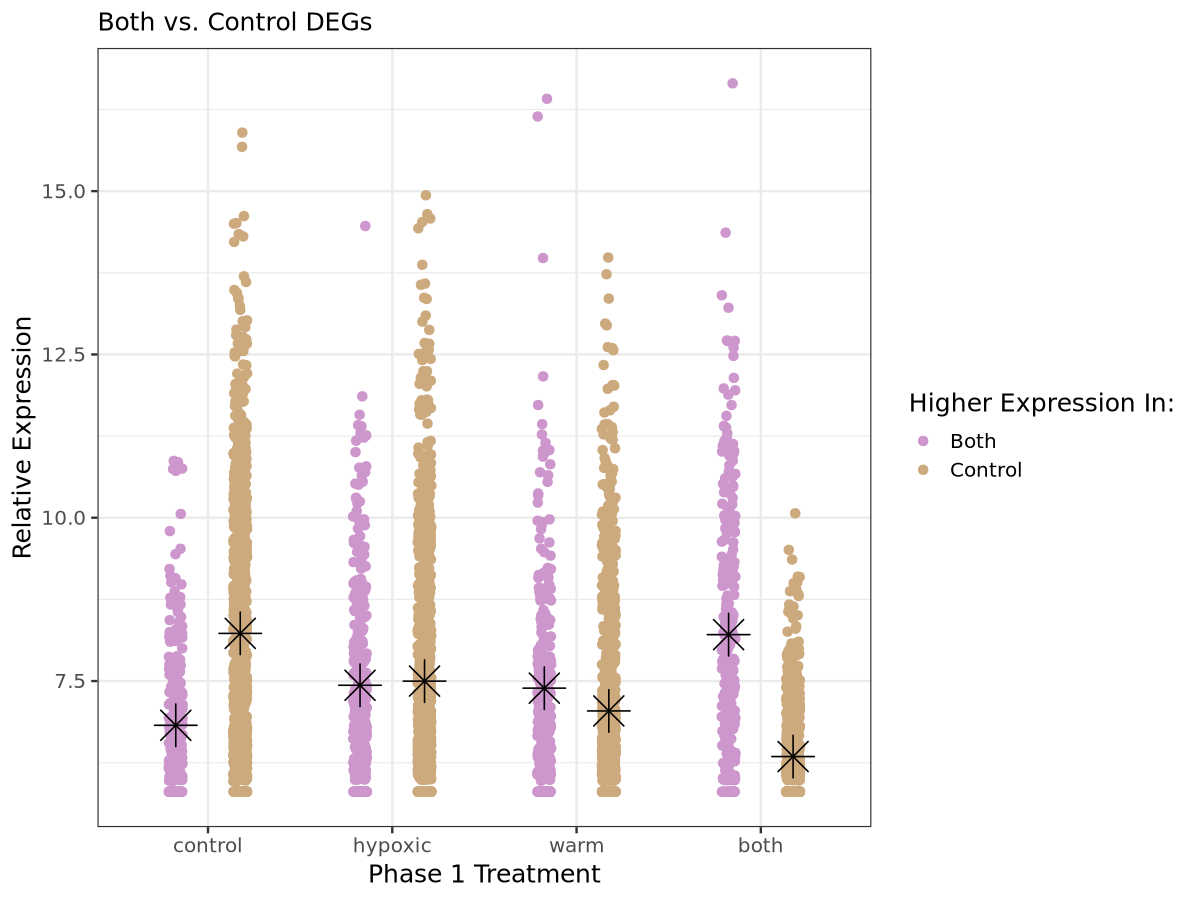

In [144]:
options(repr.plot.height = 7.5, repr.plot.width = 10)

# set dodge position
dodge <- 0.7

# set factor levels
both_deg.vst$Phase1_treatment <- factor(both_deg.vst$Phase1_treatment, levels = c('control', 'hypoxic', 'warm', 'both'))

# plot
ggplot(both_deg.vst, aes(x = Phase1_treatment, y = vst_expr,
                         col = higher_expr, group = higher_expr)) +
geom_point(position = position_jitterdodge(jitter.width = 0.15,
                                             dodge.width = dodge,
                                             seed = 1)) +
stat_summary(
    fun = "mean", 
    geom = "point", 
    position = position_dodge(width = dodge),
    shape = 8,      # asterick shape
    size = 8,        # Size of the point
    color = "black"  # Outline color
  ) +
theme_bw(base_size = 15) +
scale_color_manual(values = c('Control' = 'burlywood3', 'Both' = 'plum3')) +
labs(x = 'Phase 1 Treatment',
     y = 'Relative Expression',
     color = 'Higher Expression In:',
    subtitle = 'Both vs. Control DEGs')

In [145]:
both_deg.mat <- both_deg.vst %>% 
select(Gene, Sample, vst_expr) %>%
pivot_wider(
    names_from = Sample,
    values_from = vst_expr) %>%
column_to_rownames('Gene') %>%
as.matrix()

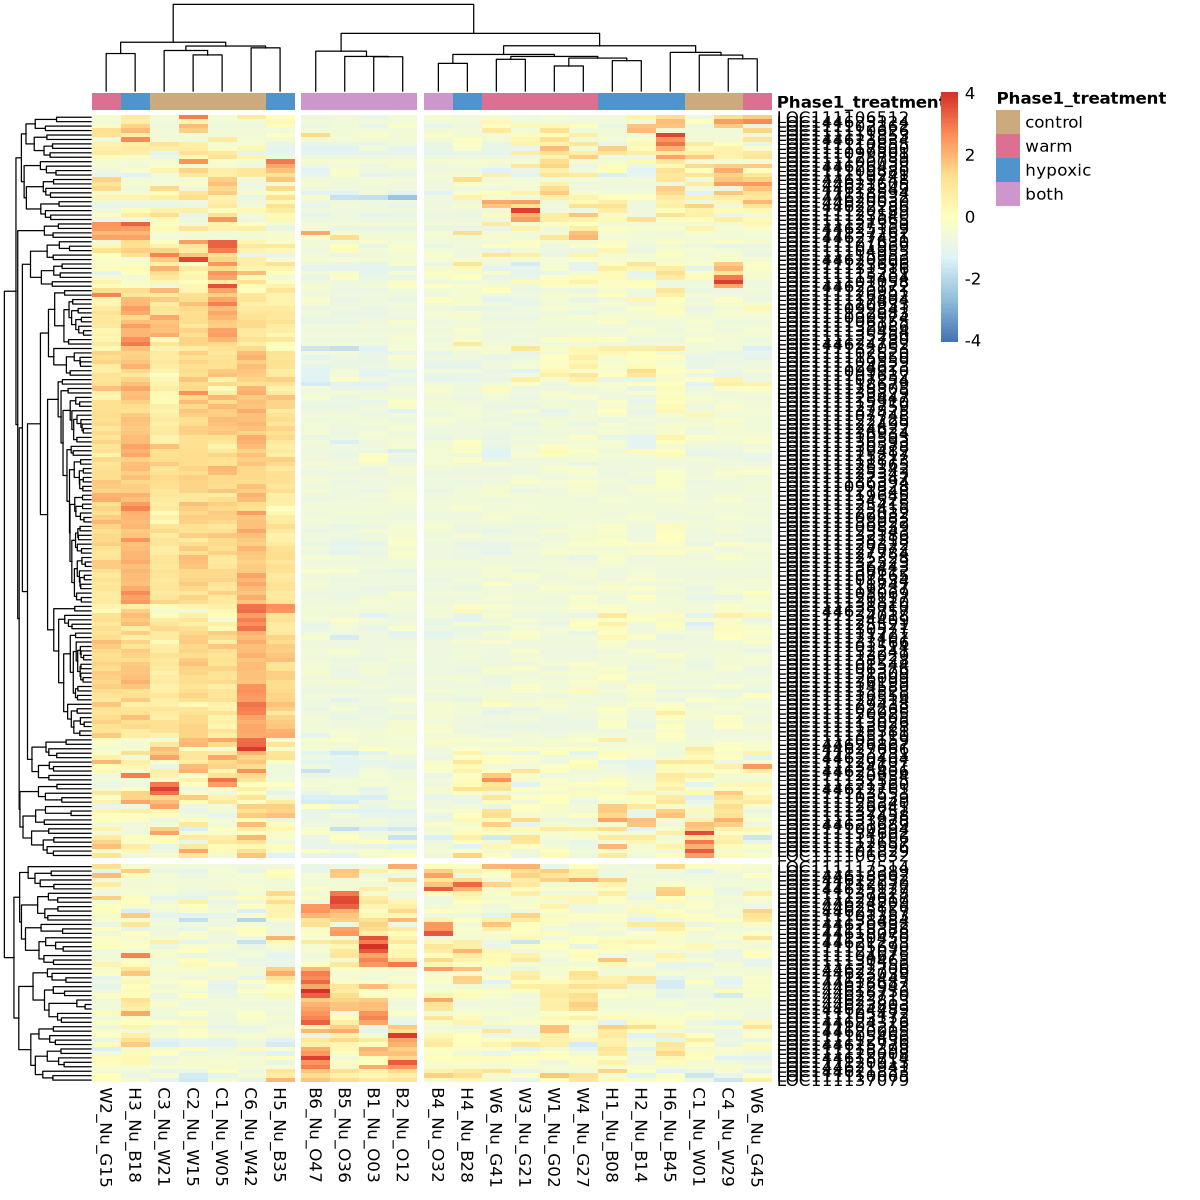

In [146]:
options(repr.plot.height = 10, repr.plot.width = 10)

pheatmap(both_deg.mat,
         # cluster_cols = FALSE,
       annotation_col = annotation,
        annotation_colors = annotation_colors,
         cutree_rows = 2, 
         cutree_cols = 3,
        scale = 'row' # standardizes each gene separately across samples
        ) 

most DEGs are downregulated in both and upregulated in control oysters - so both clumps with all the other stressors

In [147]:
cols <- colnames(both_deg.mat)

ordered <- unlist(lapply(c("C", "H", "W", "B"), function(p) {
  sort(grep(paste0("^", p), cols, value = TRUE))
}))

both_deg.mat <- both_deg.mat[, ordered]

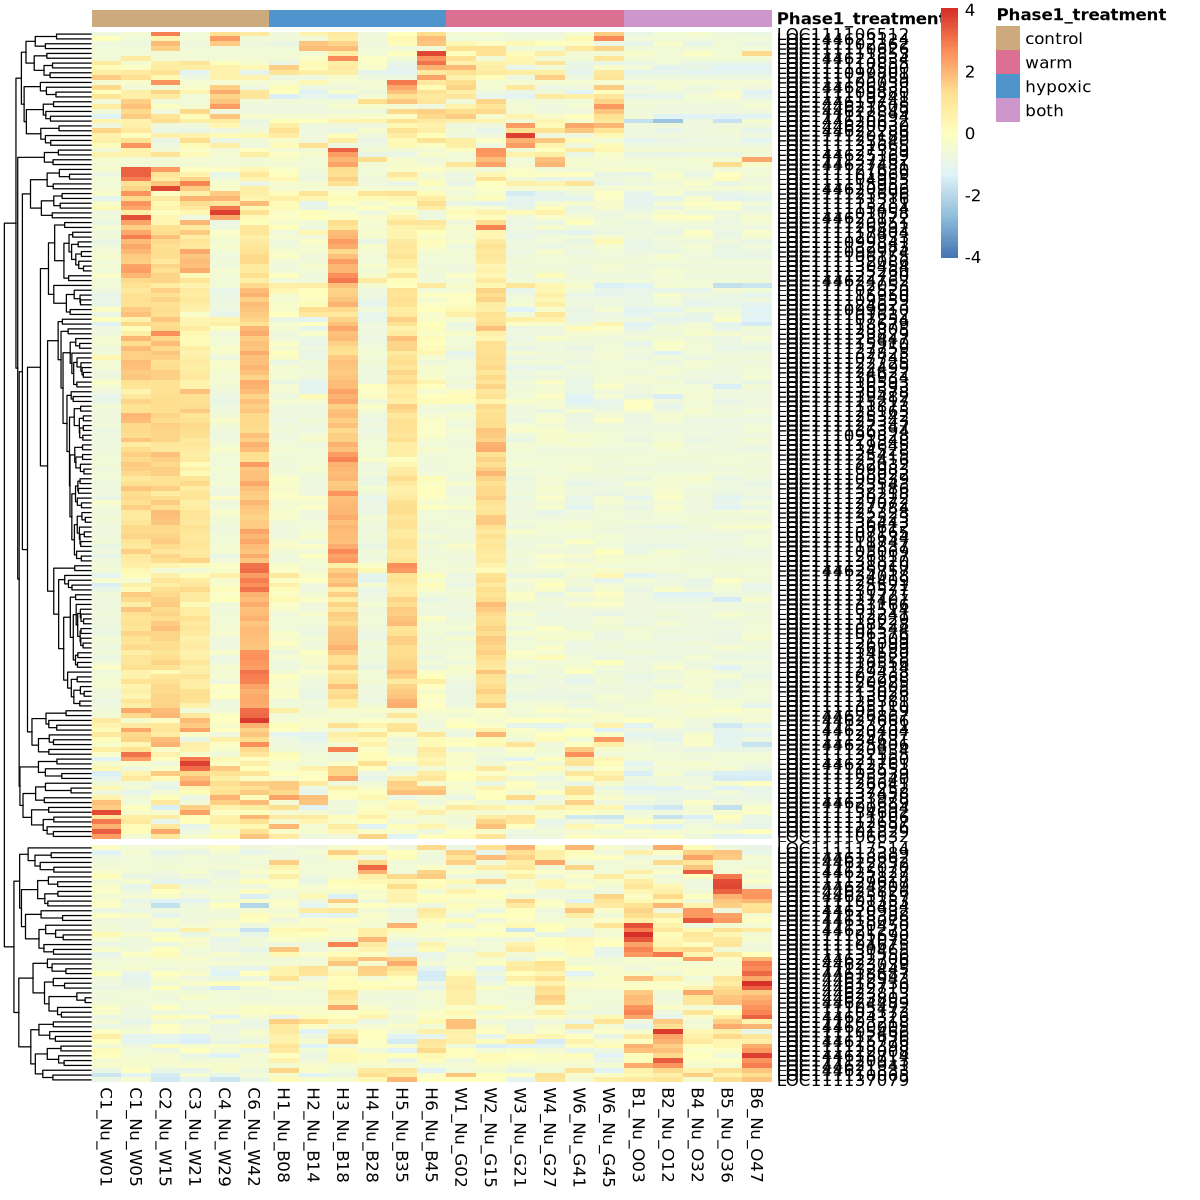

In [148]:
options(repr.plot.height = 10, repr.plot.width = 10)

pheatmap(both_deg.mat,
          cluster_cols = FALSE,
       annotation_col = annotation,
        annotation_colors = annotation_colors,
         cutree_rows = 2, 
         cutree_cols = 2,
        scale = 'row' # standardizes each gene separately across samples
        ) 

so the both treatment is really strongly downregulated in the genes that have higher expression in control - looks like there's also a lot of variaiton in expression for the hypoxic and warm oysters